In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_copy_number_heatmap
    )
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

from visualization import plot_overlap_matrix_figure

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
numb = "25"
tumor = "t"+numb

In [3]:
#bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells_with_collisions.txt", sep = "\t")#
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
#cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values

#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
previous_A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
# previous_B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
previous_C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
# previous_D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")

In [5]:
previous_A_dict = {}
for cluster in previous_A_df['population'].unique():
    print(cluster)
    cells_in_cluster = previous_A_df[previous_A_df['population'] == cluster]['cell'].tolist()
    previous_A_dict[cluster] = {
        'cells': cells_in_cluster
    }
previous_C_dict = {}
for cluster in previous_C_df['population'].unique():
    print(cluster)
    cells_in_cluster = previous_C_df[previous_C_df['population'] == cluster]['cell'].tolist()
    previous_C_dict[cluster] = {
        'cells': cells_in_cluster
    }
    

A11
A12
A211
A212
A221
A222
C11
C12
C2111
C21121
C211221
C211222
C212
C221
C222


In [6]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A_with_collisions.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B_with_collisions.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C_with_collisions.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D_with_collisions.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [7]:
cells = A_df["cell"].values

In [8]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A11
A12
A21111
A211121
A211122
A2112
A212
A221
A222


In [9]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B111111
B111112
B11112
B1112
B112
B121
B122
B21
B22


In [10]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C111111
C111112
C11112
C1112
C112
C121
C122
C21
C22


In [11]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D111
D1121
D11221
D112221
D112222
D121
D122
D21
D22


In [12]:
previous_A_dict["collisions"] = {"cells": [c for c in cells if "_" in c]}
previous_C_dict["collisions"] = {"cells": [c for c in cells if "_" in c]}

In [13]:
non_collisions = [c for c in cells if "_" not in c]
collision_cells = [c for c in cells if "_" in c]

In [14]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
#data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        #data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
#data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = bincounts[non_collisions].copy()
for cell in collision_cells:
    cell1, cell2 = cell.split("_")
    all_data[cell] = bincounts[cell1] + bincounts[cell2]
#all_data_no_WGS = data_no_WGS[cells].copy()

In [15]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A12
Mean read count ratio for population A11 relative to normal (A12): 1.27
Mean read count ratio for population A12 relative to normal (A12): 1.00
Mean read count ratio for population A21111 relative to normal (A12): 1.64
Mean read count ratio for population A211121 relative to normal (A12): 1.06
Mean read count ratio for population A211122 relative to normal (A12): 1.45
Mean read count ratio for population A2112 relative to normal (A12): 1.24
Mean read count ratio for population A212 relative to normal (A12): 1.48
Mean read count ratio for population A221 relative to normal (A12): 1.49
Mean read count ratio for population A222 relative to normal (A12): 1.22
=== Population Set B Analysis ===
Normal population identified as: B21
Mean read count ratio for population B111111 relative to normal (B21): 1.06
Mean read count ratio for population B111112 relative to normal (B21): 1.45
Mean read count ratio for population B1111

In [16]:
previous_A_dict

{'A11': {'cells': ['AAAACCAAATCCAGACT',
   'AAAACCAACAAGAGACT',
   'AAAACCAAGCGTGGTCA',
   'AAAACCAAGGCCCAACG',
   'AAAACCAAGGCCCAATA',
   'AAAACCAGTGAGATTCC',
   'AAAACCCCTGCAGTTAG',
   'AAAACCGAAGCGGCACG',
   'AAAACCTAGGAAAGACT',
   'AAAACCTATGGCTGACG',
   'AAAACCTTTACGACTAG',
   'AAAACCTTTAGTGGATT',
   'AAAATGAAAGTAGAAGA',
   'AAAATGAACCGAGATGT',
   'AAAATGAGAATTCTATC',
   'AAAATGAGAATTTATGA',
   'AAAATGAGCCTCGCATA',
   'AAAATGATCCGGGCTAA',
   'AAAATGATCGAGGGTCA',
   'AAAATGATGAGGCGAAT',
   'AAAATGCTTCCATCTAC',
   'AAAATGGAAGCGTAACA',
   'AAAATGGACTGGGATTA',
   'AAAATGGATGCAACATG',
   'AAAATGTATTCTAGAGA',
   'AAAATGTGCAGGAGATC',
   'AAAGCAAATTTCAGTGT',
   'AAAGCAACCTGCTGTAA',
   'AAAGCAATGGATCGACA',
   'AAAGCAGAACCCACAAT',
   'AAAGCAGACTGGTGTGG',
   'AAAGCAGAGGTATCTTA',
   'AAAGCAGATAGACGAAT',
   'AAAGCAGGACGTGATGT',
   'AAAGCAGTGCAAAGATC',
   'AAAGCATAAACCAGACT',
   'AAAGCATAATTTCATAA',
   'AAAGCATTCGGCATTCC',
   'AAAGCATTCGGCTATCT',
   'AAAGCATTGAGCGCTAA',
   'AAAGCATTGCTGCATCC',


In [17]:
data.head()

,chrom,abstart,abend,AAAACCAGTGAGGAACT,AAAACCATGGATGTAGC,AAAACCGACCATTTAGG,AAAACCGCCTCTAATGC,AAAATGACTGGCAATGC,AAAATGATGCACATATA,AAAATGATTCAGGAACT,...,TGATTTTGTTAAATATA,TGCTGCTAATTTGGTAT,TTGGGAGGGTTTGCAAC,TTGGGAGTGCAAGAACT,TTGGGATGTTAAGATAC,TTTCGAAATTTCGCACG,TTTCGAGTAAACTCAAG,ATTTTGGAACCCGCATA_GTTTGAAATTTCAATGC,TTGGGAAAAGGCAGTGT_TTTCGAGTAAACTCAAG,lengths
0,chr1,0,15737727,98,186,64,248,213,273,175,...,63,73,174,49,43,90,62,300,118,15737727
1,chr1,16309376,19838791,30,53,16,83,55,75,46,...,25,24,59,11,7,20,26,76,40,3529415
2,chr1,20399617,29621787,60,96,41,222,161,216,87,...,55,51,125,37,30,56,89,198,119,9222170
3,chr1,30315354,35903486,40,77,46,90,101,135,102,...,31,31,52,24,2,46,34,128,60,5588132
4,chr1,36461413,109420217,451,960,427,1162,1152,1489,612,...,460,492,1293,525,437,1018,813,2097,1117,72958804


In [18]:
avg_counts_A_prev, ratios_A_prev, normal_A_prev = compute_average_segment_counts(all_data, previous_A_dict, data)
relative_counts_A_prev = compute_read_counts_relative_to_normal(all_data, previous_A_dict, normal_A_prev)

avg_counts_C_prev, ratios_C_prev, normal_C_prev = compute_average_segment_counts(all_data, previous_C_dict, data)
relative_counts_C_prev = compute_read_counts_relative_to_normal(all_data, previous_C_dict, normal_C_prev)



Normal population identified as: A11
Mean read count ratio for population A11 relative to normal (A11): 1.00
Mean read count ratio for population A12 relative to normal (A11): 1.18
Mean read count ratio for population A211 relative to normal (A11): 1.19
Mean read count ratio for population A212 relative to normal (A11): 1.48
Mean read count ratio for population A221 relative to normal (A11): 1.28
Mean read count ratio for population A222 relative to normal (A11): 1.49
Mean read count ratio for population collisions relative to normal (A11): 2.36
Normal population identified as: C12
Mean read count ratio for population C11 relative to normal (C12): 1.15
Mean read count ratio for population C12 relative to normal (C12): 1.00
Mean read count ratio for population C2111 relative to normal (C12): 1.23
Mean read count ratio for population C21121 relative to normal (C12): 1.53
Mean read count ratio for population C211221 relative to normal (C12): 1.08
Mean read count ratio for population C2112

In [19]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [20]:
data_lengths = data["abend"] - data["abstart"]

In [21]:
readcount_dict = dict(all_data.sum())

In [22]:
# readcount_dict in increasing order by values
readcount_dict = dict(sorted(readcount_dict.items(), key=lambda item: item[1]))

In [23]:
# order A_dict["A11"]["cells"] by readcount_dict
for cluster in A_dict:
    A_dict[cluster]["cells"] = sorted(A_dict[cluster]["cells"], key=lambda cell: readcount_dict[cell])


Overlap Matrix (A rows vs B cols):
Pop          A11     A12    A211    A212    A221    A222collisions
B111111        0       2       0       0      28       0       1
B111112        0       3       0       2      36       0       3
B11112         4       7       1       0      71       4      25
B1112          0       2       0       0     241       0       8
B112           0       0       0       0       0     126       4
B121           0       0       0      58       0       0       3
B122           0       0      55       0       0       0       2
B21         1185       0       0       0       0       0      27
B22            0     203       0       0       0       0      27


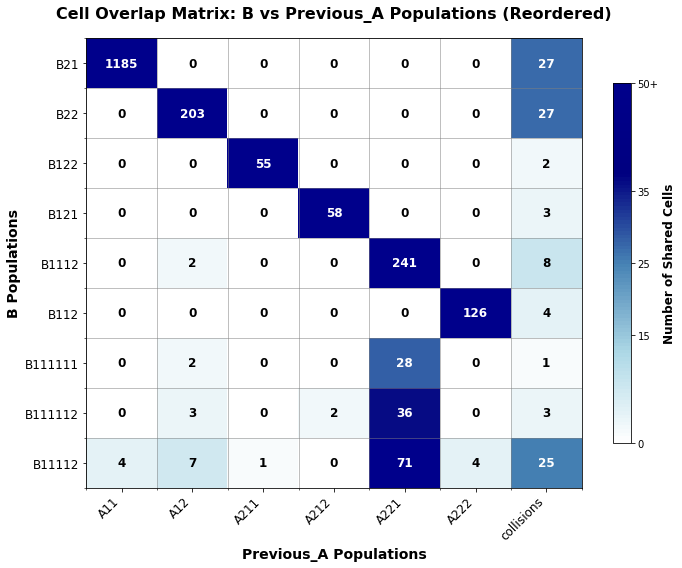

In [24]:
overlap_df = plot_overlap_matrix_figure(B_dict, previous_A_dict, name1="B", name2="Previous_A")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12   C2111  C21121 C211221 C211222    C212    C221    C222collisions
A11          203       0       0       0       0       0       0       0       0      27
A12            0    1185       0       0       0       0       0       0       0      27
A21111         0       0       0      87       0       0       0       0       0      25
A211121        0       0       0       0      30       0       0       0       0       1
A211122        0       0       0       0       0      41       0       0       0       3
A2112          0       0     243       0       0       0       0       0       0       8
A212           0       0       0       0       0       0     126       0       0       4
A221           0       0       0       0       0       0       0      58       0       3
A222           0       0       0       0       0       0       0       0      55       2


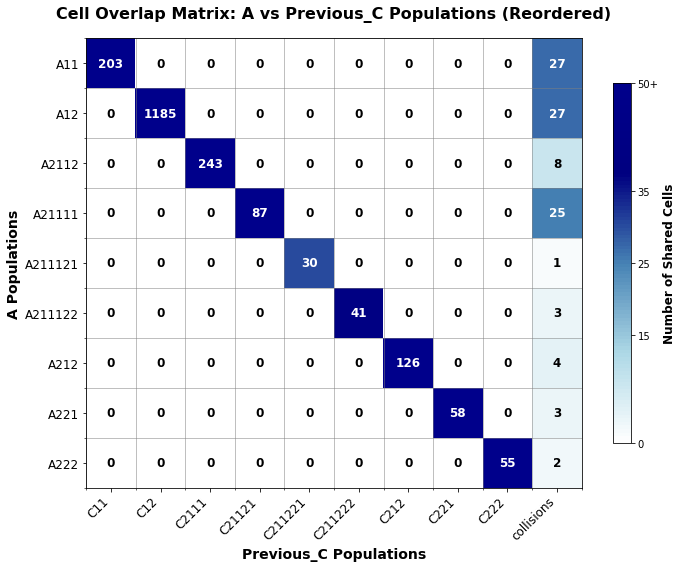

In [25]:
overlap_df = plot_overlap_matrix_figure(A_dict, previous_C_dict, name1="A", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12   C2111  C21121 C211221 C211222    C212    C221    C222collisions
B111111        0       0       0       0      30       0       0       0       0       1
B111112        0       0       0       0       0      41       0       0       0       3
B11112         0       0       0      87       0       0       0       0       0      25
B1112          0       0     243       0       0       0       0       0       0       8
B112           0       0       0       0       0       0     126       0       0       4
B121           0       0       0       0       0       0       0      58       0       3
B122           0       0       0       0       0       0       0       0      55       2
B21            0    1185       0       0       0       0       0       0       0      27
B22          203       0       0       0       0       0       0       0       0      27


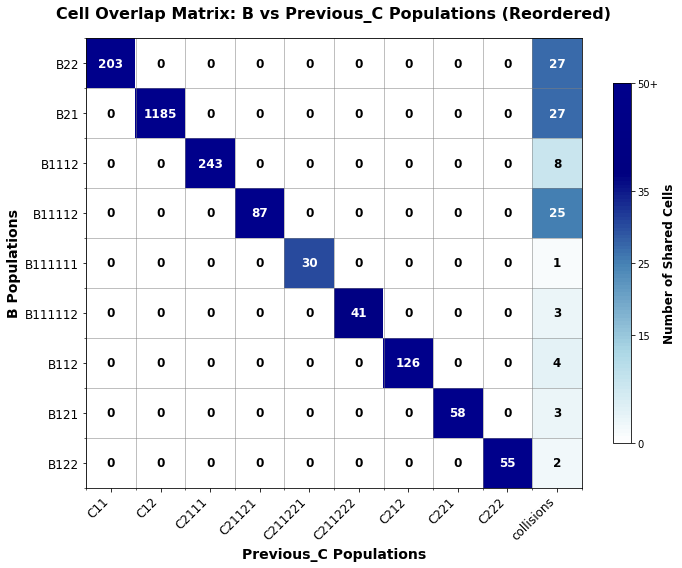

In [26]:
overlap_df = plot_overlap_matrix_figure(B_dict, previous_C_dict, name1="B", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12   C2111  C21121 C211221 C211222    C212    C221    C222collisions
C111111        0       0       0       0       0      41       0       0       0       3
C111112        0       0       0       0      30       0       0       0       0       1
C11112         0       0       0      87       0       0       0       0       0      25
C1112          0       0     242       0       0       0       0       0       0       8
C112           0       0       0       0       0       0     126       0       0       4
C121           0       0       0       0       0       0       0       0      55       2
C122           0       0       0       0       0       0       0      58       0       3
C21            2    1178       0       0       0       0       0       0       0      25
C22          201       7       1       0       0       0       0       0       0      29


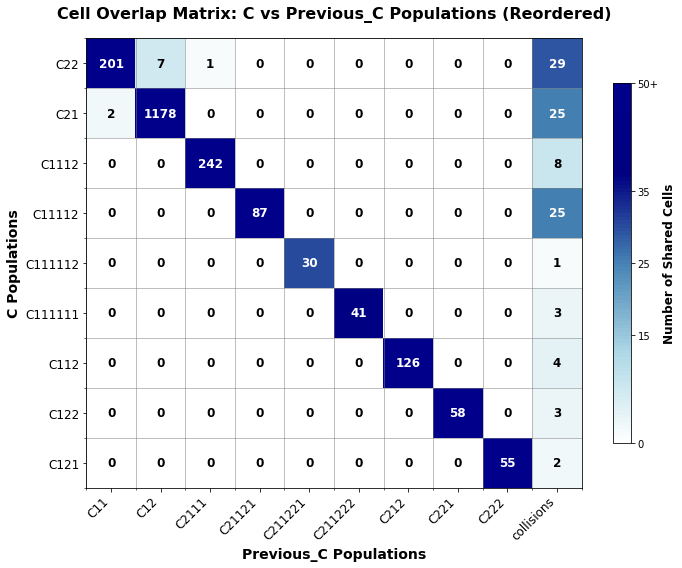

In [27]:
overlap_df = plot_overlap_matrix_figure(C_dict, previous_C_dict, name1="C", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12   C2111  C21121 C211221 C211222    C212    C221    C222collisions
D111           0       0       0       0       0       0     126       0       0       4
D1121          0       0     243       0       0       0       0       0       0       8
D11221         0       0       0      87       0       0       0       0       0      24
D112221        0       0       0       0      30       0       0       0       0       1
D112222        0       0       0       0       0      41       0       0       0       3
D121           0       0       0       0       0       0       0      58       0       3
D122           0       0       0       0       0       0       0       0      55       2
D21            2    1185       0       0       0       0       0       0       0      27
D22          201       0       0       0       0       0       0       0       0      28


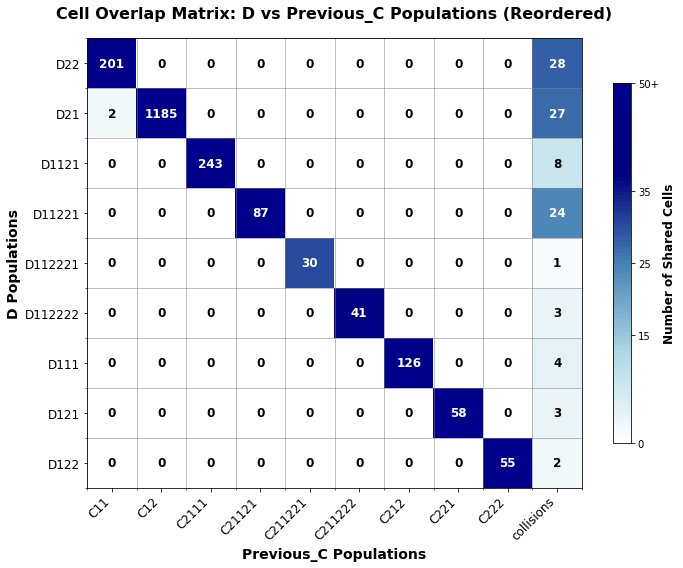

In [28]:
overlap_df = plot_overlap_matrix_figure(D_dict, previous_C_dict, name1="D", name2="Previous_C")

In [29]:
def create_copy_number_matrix_fast_new(all_data, reassigned_populations, ratios_to_normal, normal_pop_name, readcount_dict):
   
    import numpy as np
    import pandas as pd
    
    for cluster in reassigned_populations:
        reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
    # Create cell to population mapping
    cell_pop_mapping = {}
    for pop_name, pop_data in reassigned_populations.items():
        for cell in pop_data["cells"]:
            cell_pop_mapping[cell] = pop_name
    
    # Order cells by population
    ordered_cells = []
    pop_boundaries = []
    current_pos = 0
    
    # Add normal population first
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    ordered_cells.extend(normal_cells)
    current_pos += len(normal_cells)
    pop_boundaries.append((normal_pop_name, 0, current_pos))
    
    # Add other populations
    for pop_name in reassigned_populations.keys():
        if pop_name != normal_pop_name:
            pop_cells = reassigned_populations[pop_name]["cells"]
            ordered_cells.extend(pop_cells)
            start_pos = current_pos
            current_pos += len(pop_cells)
            pop_boundaries.append((pop_name, start_pos, current_pos))
    
    # Order segments by chromosome and position
    segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    segment_order['chrom_num'] = segment_order['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    ordered_segment_indices = segment_order.index
    
    # Get ordered data (this is the key optimization)
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]
    
    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")
    
    # Step 1: Compute normal_factor (segment average for normal cells)
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    
    print("Normal factor computed")
    
    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)
    
    print("Data normalized by normal factor")
    
    # # Step 3: For each cell, normalize by mean over all segments in that cell
    # cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
    # cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero
    
    # # Normalize each cell by its own mean
    # doubly_normalized_data = normalized_data.div(cell_means, axis=1)
    
    print("Data normalized by cell means")
    
    # Step 4: Apply ploidy multipliers
    heatmap_data = np.zeros_like(normalized_data.values, dtype=float)
    
    for i, cell in enumerate(ordered_cells):
        cell_pop = cell_pop_mapping[cell]
        
        # # Get appropriate multiplier
        # if cell_pop == normal_pop_name:
        #     multiplier = 2.0  # Normal cells get multiplier of 2
        # else:
        #     pop_ratio_col = f"{cell_pop}_ratio"
        #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
        
        multiplier = 2
        # Apply multiplier to this cell's data
        heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier
    
    print("Ploidy multipliers applied")
    
    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]
    
    # Create heatmap DataFrame
    heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)
    
    # Create segment info DataFrame
    segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
    segment_info.index = segment_labels
    
    print("Copy number matrix created successfully!")
    
    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info


In [30]:
#heatmap_df_A, cell_pop_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast_new(all_data, A_dict, ratios_A, normal_A, readcount_dict)

In [31]:
# plot_copy_number_heatmap(
#     heatmap_df_A, 
#     boundaries_A, 
#     segment_info_A,
#     title="Copy Number Heatmap: Population Set A"
# )


In [32]:
# heatmap_df_D, cell_pop_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast_new(all_data, D_dict, ratios_D, normal_D, readcount_dict)

In [33]:
# plot_copy_number_heatmap(
#     heatmap_df_D, 
#     boundaries_D, 
#     segment_info_D,
#     title="Copy Number Heatmap: Population Set D"
# )

In [34]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,TGGCCTGAGGTAACACA,TGCCAAAAGCGTTTATT,GCAAATACCTGCCGTCT,GTTAAGTTTAGTGTAGC,GCATCGACATGAACAGC,...,TATTTGGATAGAGTTCT_AAATCGTTCCAGACAGC,GTAACCGTTAGCTGAGT_GAAGCCTAAACCAGAAG,GGGTCTGAACAATCATC_GTTTCGTGAACAATTCC,GTTTCGAAATCCTCTGT_TTTTGGGAACAACAACG,TTGGACAGTGAGACTAG_TTGCGTACATGAACTAG,GTGCATGTTAGCTGATA_GCAAATAAGCGTGATTA,TGAAACGGCTATGTACA_AGCGAATAAACCTGACG,GGGATCAACCTGTATAG_TGCCAAGCCTCTTGAAC,ATGGTTTTAAGGAGAAG_AGCAATGGTGACCTAAG,ATAGCCTGTTAAGCATA_CAGGCAATTGGTGTAGC
0,chr1,0,15737727,0,15737727,365,305,311,289,212,...,408,316,235,286,273,430,260,165,248,291
1,chr1,16309376,19838791,16309376,19838791,114,68,84,91,51,...,100,100,59,70,79,113,74,54,54,54
2,chr1,20399617,29621787,20399617,29621787,238,210,251,205,118,...,281,200,193,183,198,264,204,110,160,169
3,chr1,30315354,35903486,30315354,35903486,93,109,97,133,91,...,150,84,99,69,91,152,128,69,71,105
4,chr1,36461413,109420217,36461413,109420217,2070,1806,1970,1868,1948,...,2211,1667,1667,1229,1564,2291,1225,1545,1209,1677


In [35]:
reassigned_populations = A_dict  # or D_dict, depending on which one you want to use    
normal_pop_name = normal_A  # or normal_D, depending on which one you want to use
ratios_to_normal = ratios_A  # or ratios_D, depending on which one you want to use

for cluster in reassigned_populations:
    reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
# Create cell to population mapping
cell_pop_mapping = {}
for pop_name, pop_data in reassigned_populations.items():
    for cell in pop_data["cells"]:
        cell_pop_mapping[cell] = pop_name

# Order cells by population
ordered_cells = []
pop_boundaries = []
current_pos = 0

# Add normal population first
normal_cells = reassigned_populations[normal_pop_name]["cells"]
ordered_cells.extend(normal_cells)
current_pos += len(normal_cells)
pop_boundaries.append((normal_pop_name, 0, current_pos))

# Add other populations
for pop_name in reassigned_populations.keys():
    if pop_name != normal_pop_name:
        pop_cells = reassigned_populations[pop_name]["cells"]
        ordered_cells.extend(pop_cells)
        start_pos = current_pos
        current_pos += len(pop_cells)
        pop_boundaries.append((pop_name, start_pos, current_pos))

# Order segments by chromosome and position
segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
segment_order['chrom_num'] = segment_order['chrom'].apply(
    lambda x: chrom_order.index(x) if x in chrom_order else 999
)
segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
ordered_segment_indices = segment_order.index

# Get ordered data (this is the key optimization)
ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]

print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")

# Step 1: Compute normal_factor (segment average for normal cells)
normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
normal_factor = normal_factor/normal_factor.mean()  # Normalize normal_factor to have mean of 1

print("Normal factor computed")

ordered_data = ordered_data/ordered_data.mean(axis=0)



Processing 52 segments using vectorized operations...
Normal factor computed


In [36]:
# Step 2: Normalize all cells by normal_factor
normalized_data = ordered_data.div(normal_factor, axis=0)

print("Data normalized by normal factor")

# # Step 3: For each cell, normalize by mean over all segments in that cell
# cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
# cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero

# # Normalize each cell by its own mean
# doubly_normalized_data = normalized_data.div(cell_means, axis=1)

print("Data normalized by cell means")

# Step 4: Apply ploidy multipliers
heatmap_data = np.zeros_like(normalized_data.values, dtype=float)

for i, cell in enumerate(ordered_cells):
    cell_pop = cell_pop_mapping[cell]
    
    # # Get appropriate multiplier
    # if cell_pop == normal_pop_name:
    #     multiplier = 2.0  # Normal cells get multiplier of 2
    # else:
    #     pop_ratio_col = f"{cell_pop}_ratio"
    #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
    
    multiplier = 2
    # Apply multiplier to this cell's data
    heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier

print("Ploidy multipliers applied")

# Create segment labels
segment_labels = [
    f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
    for seg_idx in ordered_segment_indices
]

# Create heatmap DataFrame
heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)

# Create segment info DataFrame
segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
segment_info.index = segment_labels

print("Copy number matrix created successfully!")


Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


In [37]:
def create_copy_number_matrix_new(all_data, reassigned_populations, ratios_to_normal, normal_pop_name, readcount_dict):
   
    import numpy as np
    import pandas as pd
    
    for cluster in reassigned_populations:
        reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
    # Create cell to population mapping
    cell_pop_mapping = {}
    for pop_name, pop_data in reassigned_populations.items():
        for cell in pop_data["cells"]:
            cell_pop_mapping[cell] = pop_name
    
    # Order cells by population
    ordered_cells = []
    pop_boundaries = []
    current_pos = 0
    
    # Add normal population first
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    ordered_cells.extend(normal_cells)
    current_pos += len(normal_cells)
    pop_boundaries.append((normal_pop_name, 0, current_pos))
    
    # Add other populations
    for pop_name in reassigned_populations.keys():
        if pop_name != normal_pop_name:
            pop_cells = reassigned_populations[pop_name]["cells"]
            ordered_cells.extend(pop_cells)
            start_pos = current_pos
            current_pos += len(pop_cells)
            pop_boundaries.append((pop_name, start_pos, current_pos))
    
    # Order segments by chromosome and position
    segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    segment_order['chrom_num'] = segment_order['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    ordered_segment_indices = segment_order.index
    
    # Get ordered data (this is the key optimization)
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]
    
    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")
    
    # Step 1: Compute normal_factor (segment average for normal cells)
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
    normal_factor = normal_factor/normal_factor.mean()  # Normalize normal_factor to have mean of 1

    print("Normal factor computed")

    ordered_data = ordered_data/ordered_data.mean(axis=0)

    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)
    
    print("Data normalized by normal factor")
    
    # # Step 3: For each cell, normalize by mean over all segments in that cell
    # cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
    # cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero
    
    # # Normalize each cell by its own mean
    # doubly_normalized_data = normalized_data.div(cell_means, axis=1)
    
    print("Data normalized by cell means")
    
    # Step 4: Apply ploidy multipliers
    heatmap_data = np.zeros_like(normalized_data.values, dtype=float)
    
    for i, cell in enumerate(ordered_cells):
        cell_pop = cell_pop_mapping[cell]
        
        # # Get appropriate multiplier
        # if cell_pop == normal_pop_name:
        #     multiplier = 2.0  # Normal cells get multiplier of 2
        # else:
        #     pop_ratio_col = f"{cell_pop}_ratio"
        #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
        
        multiplier = 2
        # Apply multiplier to this cell's data
        heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier
    
    print("Ploidy multipliers applied")
    
    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]
    
    # Create heatmap DataFrame
    heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)
    
    # Create segment info DataFrame
    segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
    segment_info.index = segment_labels
    
    print("Copy number matrix created successfully!")
    
    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info, normalized_data


In [38]:
heatmap_df_A, cell_pop_mapping_A, boundaries_A, segment_info_A , normalized_data_A = create_copy_number_matrix_new(all_data, A_dict, ratios_A, normal_A, readcount_dict)

Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


Expanding heatmap from 52 segments to 5362 rows...

Chromosome representation in heatmap:
chr1: 440 rows, 244,886,101 bp total
chr2: 428 rows, 237,426,934 bp total
chr3: 355 rows, 196,699,981 bp total
chr4: 341 rows, 189,233,734 bp total
chr5: 325 rows, 180,137,390 bp total
chr6: 307 rows, 170,376,978 bp total
chr7: 286 rows, 158,562,752 bp total
chr8: 258 rows, 142,914,367 bp total
chr9: 236 rows, 131,151,738 bp total
chr10: 243 rows, 134,867,091 bp total
chr11: 242 rows, 134,391,747 bp total
chr12: 240 rows, 133,086,145 bp total
chr13: 206 rows, 114,445,551 bp total
chr14: 192 rows, 106,708,210 bp total
chr15: 182 rows, 101,105,309 bp total
chr16: 140 rows, 77,867,977 bp total
chr17: 139 rows, 78,050,232 bp total
chr18: 140 rows, 77,454,799 bp total
chr19: 104 rows, 57,426,592 bp total
chr20: 112 rows, 62,361,273 bp total
chr21: 77 rows, 42,608,346 bp total
chr22: 91 rows, 50,638,503 bp total
chrX: 278 rows, 154,549,132 bp total


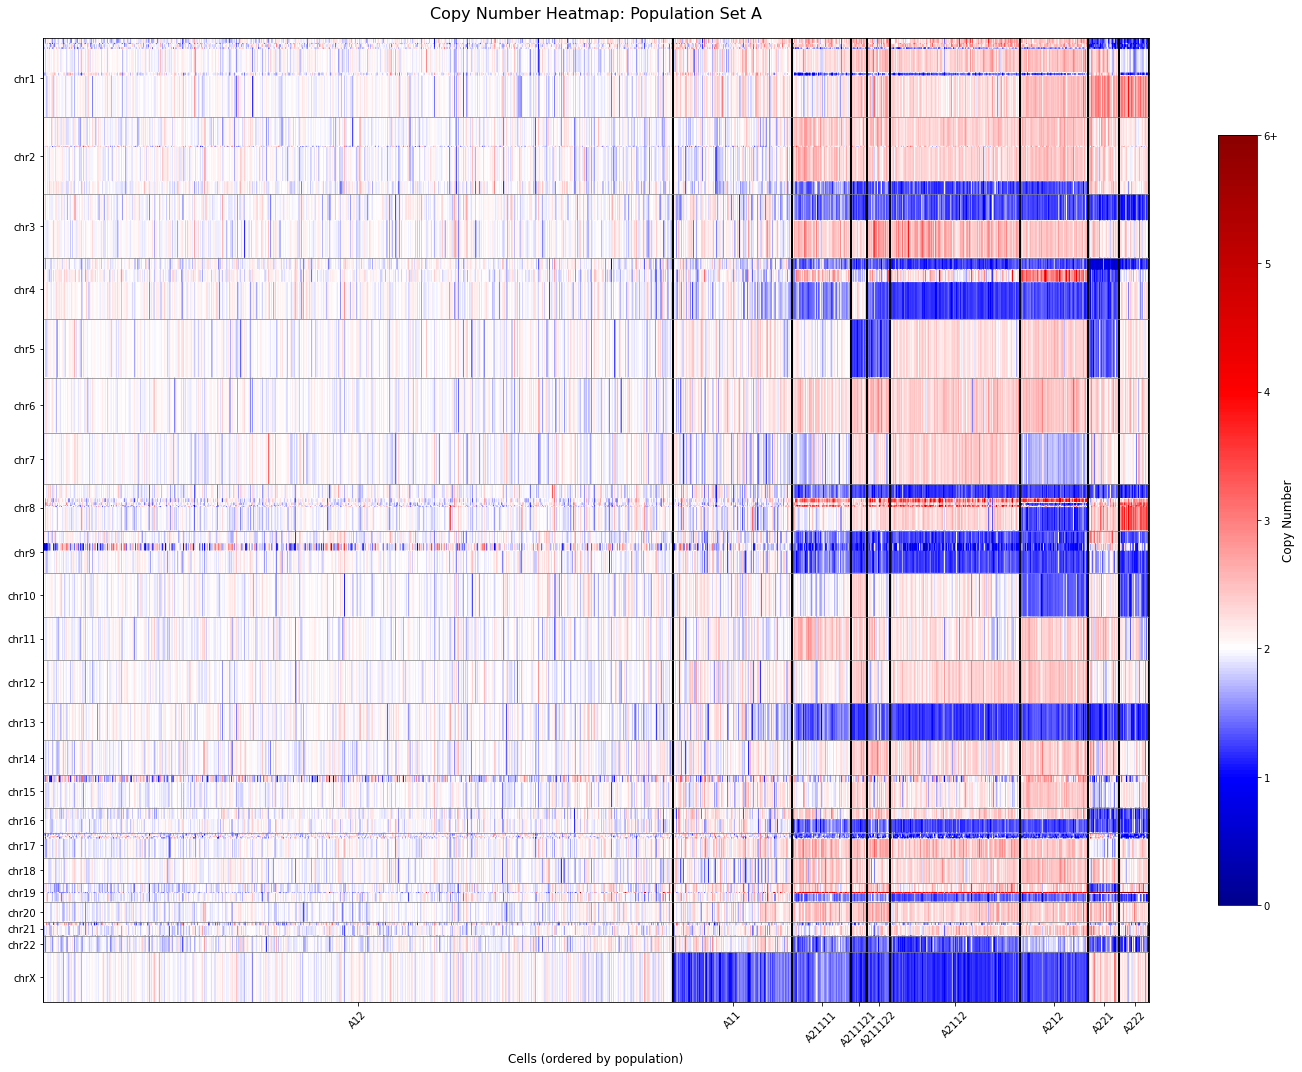

In [39]:
plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [40]:
heatmap_df_D, cell_pop_mapping_D, boundaries_D, segment_info_D, normalized_data_D = create_copy_number_matrix_new(all_data, D_dict, ratios_D, normal_D, readcount_dict)

Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


In [41]:
heatmap_df_B, cell_pop_mapping_B, boundaries_B, segment_info_B, normalized_data_B = create_copy_number_matrix_new(all_data, B_dict, ratios_B, normal_B, readcount_dict)
heatmap_df_C, cell_pop_mapping_C, boundaries_C, segment_info_C, normalized_data_C = create_copy_number_matrix_new(all_data, C_dict, ratios_C, normal_C, readcount_dict)

Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


Expanding heatmap from 52 segments to 5362 rows...

Chromosome representation in heatmap:
chr1: 440 rows, 244,886,101 bp total
chr2: 428 rows, 237,426,934 bp total
chr3: 355 rows, 196,699,981 bp total
chr4: 341 rows, 189,233,734 bp total
chr5: 325 rows, 180,137,390 bp total
chr6: 307 rows, 170,376,978 bp total
chr7: 286 rows, 158,562,752 bp total
chr8: 258 rows, 142,914,367 bp total
chr9: 236 rows, 131,151,738 bp total
chr10: 243 rows, 134,867,091 bp total
chr11: 242 rows, 134,391,747 bp total
chr12: 240 rows, 133,086,145 bp total
chr13: 206 rows, 114,445,551 bp total
chr14: 192 rows, 106,708,210 bp total
chr15: 182 rows, 101,105,309 bp total
chr16: 140 rows, 77,867,977 bp total
chr17: 139 rows, 78,050,232 bp total
chr18: 140 rows, 77,454,799 bp total
chr19: 104 rows, 57,426,592 bp total
chr20: 112 rows, 62,361,273 bp total
chr21: 77 rows, 42,608,346 bp total
chr22: 91 rows, 50,638,503 bp total
chrX: 278 rows, 154,549,132 bp total


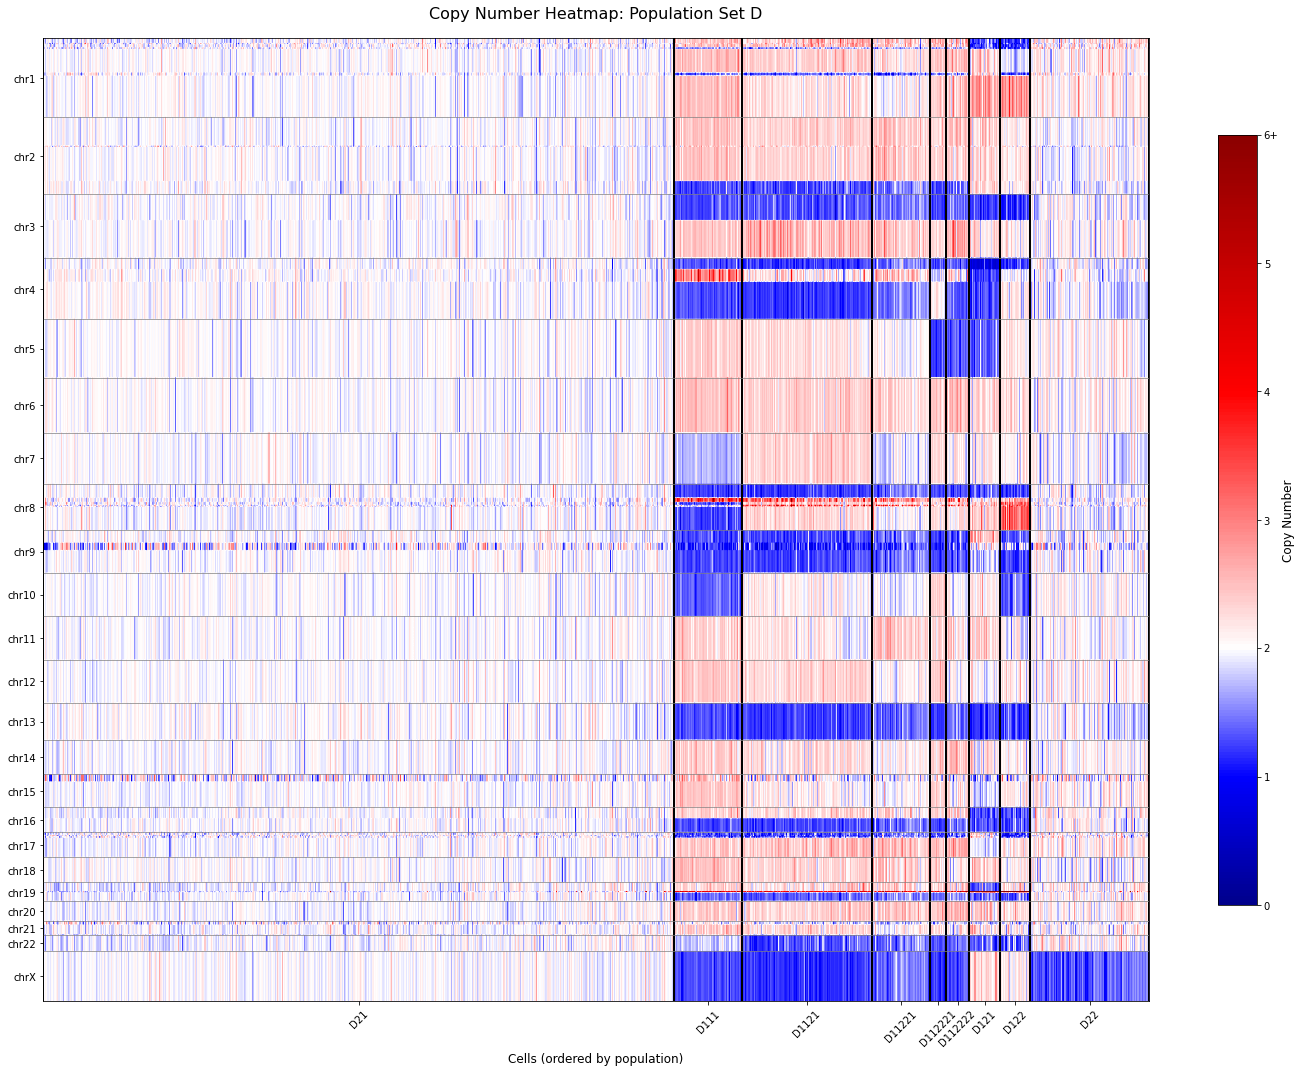

In [42]:
plot_copy_number_heatmap(
    heatmap_df_D, 
    boundaries_D, 
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

Expanding heatmap from 52 segments to 5362 rows...

Chromosome representation in heatmap:
chr1: 440 rows, 244,886,101 bp total
chr2: 428 rows, 237,426,934 bp total
chr3: 355 rows, 196,699,981 bp total
chr4: 341 rows, 189,233,734 bp total
chr5: 325 rows, 180,137,390 bp total
chr6: 307 rows, 170,376,978 bp total
chr7: 286 rows, 158,562,752 bp total
chr8: 258 rows, 142,914,367 bp total
chr9: 236 rows, 131,151,738 bp total
chr10: 243 rows, 134,867,091 bp total
chr11: 242 rows, 134,391,747 bp total
chr12: 240 rows, 133,086,145 bp total
chr13: 206 rows, 114,445,551 bp total
chr14: 192 rows, 106,708,210 bp total
chr15: 182 rows, 101,105,309 bp total
chr16: 140 rows, 77,867,977 bp total
chr17: 139 rows, 78,050,232 bp total
chr18: 140 rows, 77,454,799 bp total
chr19: 104 rows, 57,426,592 bp total
chr20: 112 rows, 62,361,273 bp total
chr21: 77 rows, 42,608,346 bp total
chr22: 91 rows, 50,638,503 bp total
chrX: 278 rows, 154,549,132 bp total


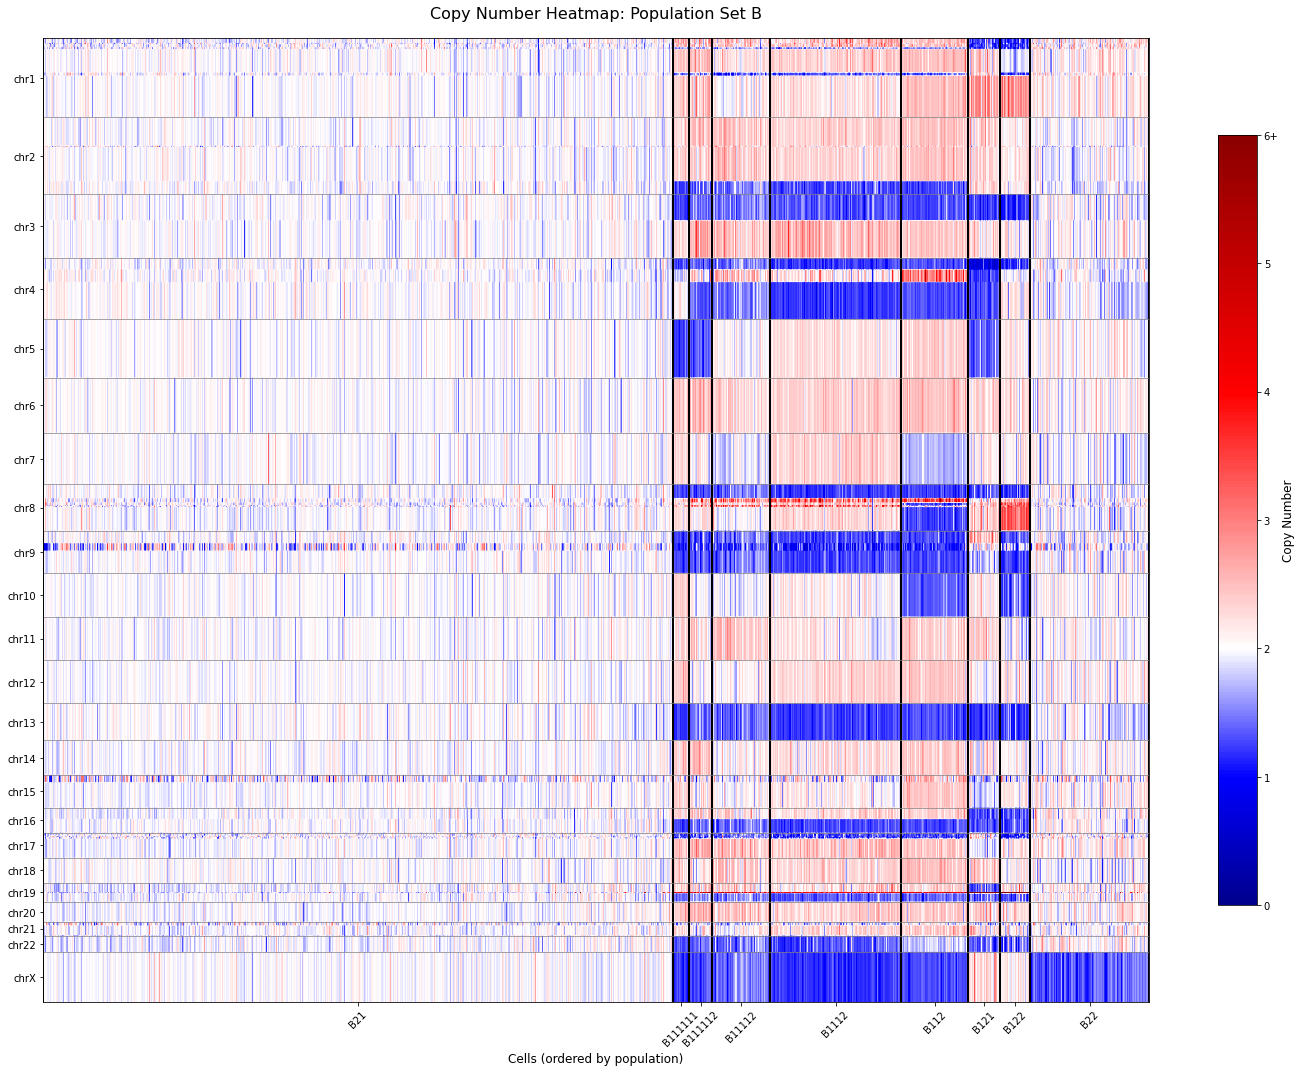

In [43]:
plot_copy_number_heatmap(
    heatmap_df_B, 
    boundaries_B, 
    segment_info_B,
    title="Copy Number Heatmap: Population Set B"
)

Expanding heatmap from 52 segments to 5362 rows...

Chromosome representation in heatmap:
chr1: 440 rows, 244,886,101 bp total
chr2: 428 rows, 237,426,934 bp total
chr3: 355 rows, 196,699,981 bp total
chr4: 341 rows, 189,233,734 bp total
chr5: 325 rows, 180,137,390 bp total
chr6: 307 rows, 170,376,978 bp total
chr7: 286 rows, 158,562,752 bp total
chr8: 258 rows, 142,914,367 bp total
chr9: 236 rows, 131,151,738 bp total
chr10: 243 rows, 134,867,091 bp total
chr11: 242 rows, 134,391,747 bp total
chr12: 240 rows, 133,086,145 bp total
chr13: 206 rows, 114,445,551 bp total
chr14: 192 rows, 106,708,210 bp total
chr15: 182 rows, 101,105,309 bp total
chr16: 140 rows, 77,867,977 bp total
chr17: 139 rows, 78,050,232 bp total
chr18: 140 rows, 77,454,799 bp total
chr19: 104 rows, 57,426,592 bp total
chr20: 112 rows, 62,361,273 bp total
chr21: 77 rows, 42,608,346 bp total
chr22: 91 rows, 50,638,503 bp total
chrX: 278 rows, 154,549,132 bp total


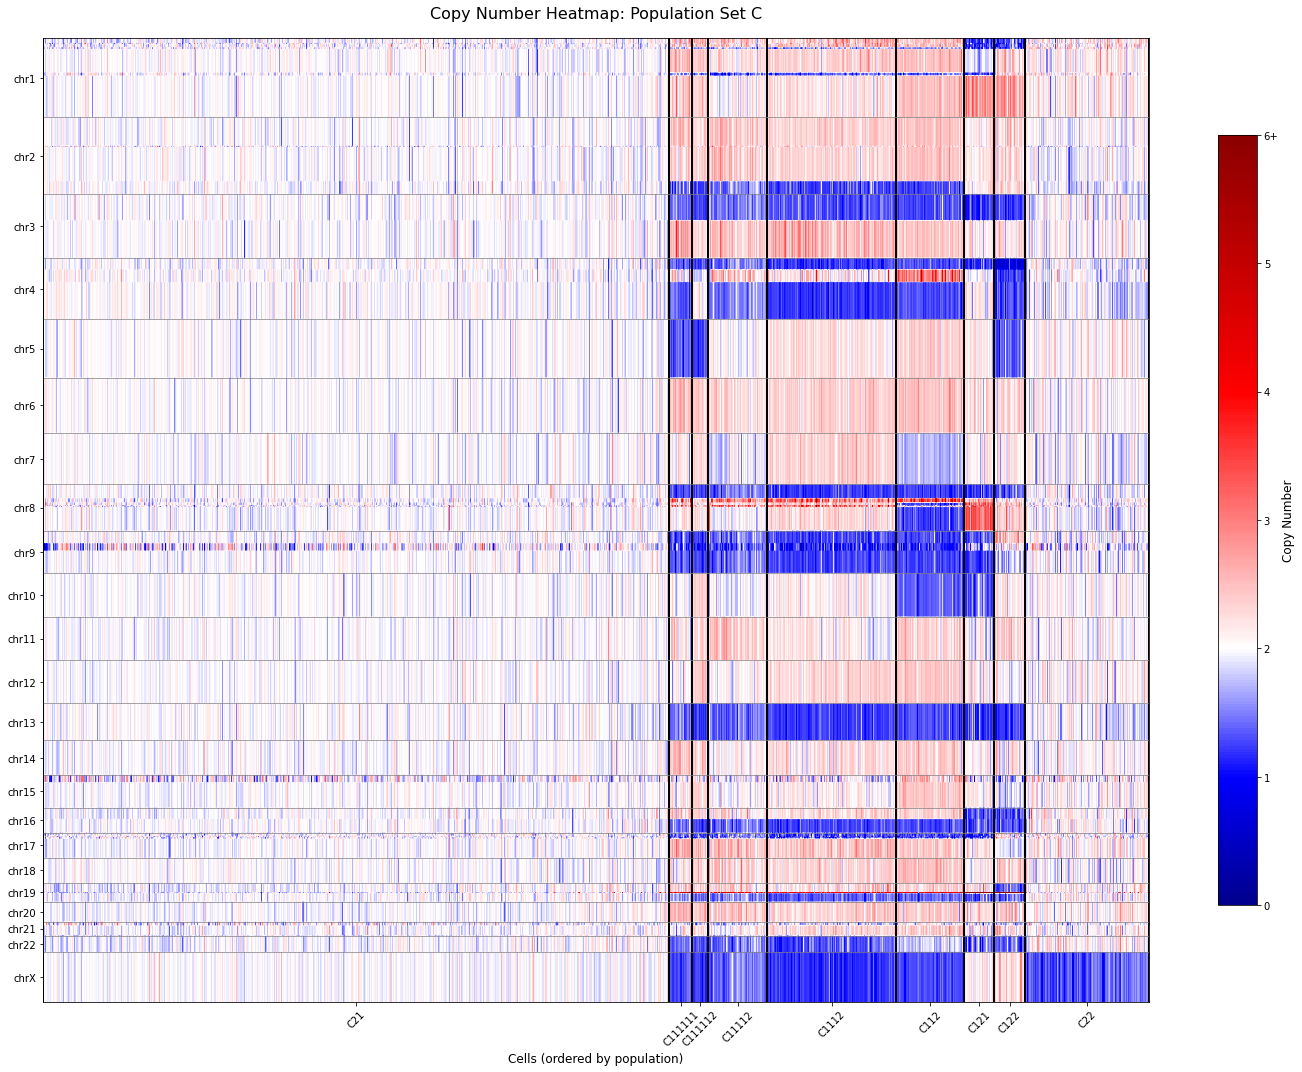

In [44]:
plot_copy_number_heatmap(
    heatmap_df_C, 
    boundaries_C, 
    segment_info_C,
    title="Copy Number Heatmap: Population Set C"
)

In [45]:
heatmap_df_A_p, cell_pop_mapping_A_p, boundaries_A_p, segment_info_A_p, normalized_data_A_p = create_copy_number_matrix_new(all_data, previous_A_dict, ratios_A_prev, normal_A_prev, readcount_dict)
heatmap_df_C, cell_pop_mapping_C_p, boundaries_C_p, segment_info_C_p, normalized_data_C_p = create_copy_number_matrix_new(all_data, previous_C_dict, ratios_C_prev, normal_C_prev, readcount_dict)

Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Processing 52 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


In [46]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,TGGCCTGAGGTAACACA,TGCCAAAAGCGTTTATT,GCAAATACCTGCCGTCT,GTTAAGTTTAGTGTAGC,GCATCGACATGAACAGC,...,TATTTGGATAGAGTTCT_AAATCGTTCCAGACAGC,GTAACCGTTAGCTGAGT_GAAGCCTAAACCAGAAG,GGGTCTGAACAATCATC_GTTTCGTGAACAATTCC,GTTTCGAAATCCTCTGT_TTTTGGGAACAACAACG,TTGGACAGTGAGACTAG_TTGCGTACATGAACTAG,GTGCATGTTAGCTGATA_GCAAATAAGCGTGATTA,TGAAACGGCTATGTACA_AGCGAATAAACCTGACG,GGGATCAACCTGTATAG_TGCCAAGCCTCTTGAAC,ATGGTTTTAAGGAGAAG_AGCAATGGTGACCTAAG,ATAGCCTGTTAAGCATA_CAGGCAATTGGTGTAGC
0,chr1,0,15737727,0,15737727,365,305,311,289,212,...,408,316,235,286,273,430,260,165,248,291
1,chr1,16309376,19838791,16309376,19838791,114,68,84,91,51,...,100,100,59,70,79,113,74,54,54,54
2,chr1,20399617,29621787,20399617,29621787,238,210,251,205,118,...,281,200,193,183,198,264,204,110,160,169
3,chr1,30315354,35903486,30315354,35903486,93,109,97,133,91,...,150,84,99,69,91,152,128,69,71,105
4,chr1,36461413,109420217,36461413,109420217,2070,1806,1970,1868,1948,...,2211,1667,1667,1229,1564,2291,1225,1545,1209,1677


In [47]:
def new_ratios_to_normal(ratios_to_normal, reassigned_populations, all_data, normal_pop_name):
    df = ratios_to_normal[['chrom', 'start', 'end']].copy()
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    normal_factor = all_data[normal_cells].mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
    normal_factor = normal_factor/normal_factor.mean() 
    for clusters in reassigned_populations:
        cells = reassigned_populations[clusters]["cells"]
        df[clusters] = all_data[cells].mean(axis=1)
        df[clusters] = df[clusters]/df[clusters].mean(axis=0)
        df[clusters] = df[clusters]/normal_factor
    return df
    

In [48]:
df_A = new_ratios_to_normal(ratios_A, A_dict, all_data, normal_A)

In [49]:
df_A.head()

,chrom,start,end,A11,A12,A21111,A211121,A211122,A2112,A212,A221,A222
0,chr1,0,15737727,1.111090,1.0,1.185958,1.251475,1.274789,1.274372,1.247812,0.687496,0.629987
1,chr1,16309376,19838791,1.083437,1.0,1.144893,1.214727,1.255243,1.263028,1.214274,0.618887,0.622387
2,chr1,20399617,29621787,1.099967,1.0,1.159724,1.228290,1.222457,1.281476,1.238125,0.658215,0.640345
3,chr1,30315354,35903486,1.107880,1.0,0.814278,0.777384,0.838737,0.796331,0.762703,0.650875,0.626906
4,chr1,36461413,109420217,1.069675,1.0,1.108924,1.189229,1.266131,1.191439,1.255194,1.166445,0.940356


In [50]:
def plot_ratios_histograms(df, reassigned_populations):
    for cluster in reassigned_populations:
        plt.figure(figsize=(10, 5))
        plt.hist(df[cluster].values, bins=50)
        plt.title(cluster)
        plt.xlim(0,3)

    #Make a nice plot for the above histograms
    plt.figure(figsize=(12, 6))
    for i, cluster in enumerate(reassigned_populations):
        plt.subplot(1, len(reassigned_populations), i+1)
        plt.hist(df[cluster], bins=50, color='blue', alpha=0.7)
        plt.title(cluster)
        plt.xlabel('Normalized Read Count')
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

In [51]:
#plot_ratios_histograms(df_A, A_dict)

In [52]:
normal_A_readcount = np.mean([readcount_dict[cell] for cell in A_dict[normal_A]["cells"]])
# for cluster in A_dict:
#     cells = A_dict[cluster]["cells"]
#     fusions = [c for c in cells if "_" in c]
#     not_fusions = [c for c in cells if "_" not in c]
#     print(len(fusions))
#     plt.hist(normalized_data_D[cells].values.ravel(), bins =500)
#     plt.title(cluster + " no multiplier")
#     plt.xlim(0,4)
#     plt.show()
#     cluster_readcount = np.mean([readcount_dict[cell] for cell in cells])
#     readcount_factor = (cluster_readcount/normal_A_readcount)*2
#     plt.hist(normalized_data_D[cells].values.ravel()*readcount_factor, bins =500)
#     plt.title(cluster + " readcount multiplier "+ str(round(readcount_factor, 2)))
#     plt.xlim(0,4*readcount_factor)
#     plt.show()
#     if len(fusions) > 20:
#         cluster_readcount = np.mean([readcount_dict[cell] for cell in fusions])
#         readcount_factor = (cluster_readcount/normal_A_readcount)*2
#         plt.hist(normalized_data_D[fusions].values.ravel()*readcount_factor, bins =500)
#         plt.title(cluster + " fusions readcount multiplier "+ str(round(readcount_factor, 2)))
#         #x ticks at integers
#         plt.xticks(np.arange(0, 4*readcount_factor+1, 1))
#         plt.xlim(0,4*readcount_factor)
#         plt.show()
#         cluster_readcount = np.mean([readcount_dict[cell] for cell in not_fusions])
#         readcount_factor = (cluster_readcount/normal_A_readcount)*2
#         plt.hist(normalized_data_D[not_fusions].values.ravel()*readcount_factor, bins =500)
#         plt.title(cluster + " not fusions readcount multiplier "+ str(round(readcount_factor, 2)))
#         plt.xlim(0,4*readcount_factor)
#         plt.show()

In [53]:
# for cluster in D_dict:
#     cells = D_dict[cluster]["cells"]
#     plt.hist(normalized_data_D[cells].values.ravel(), bins =500)
#     plt.title(cluster)
#     plt.xlim(0,4)
#     plt.show()

In [54]:
# for cluster in A_dict:
#     cells = A_dict[cluster]["cells"]
#     plt.hist(normalized_data_A[cells].values.ravel(), bins =800)
#     plt.title(cluster)
#     plt.xlim(0,4)
#     plt.show()

In [55]:
def histograms_from_bootstrap(all_data, normalized_data, reassigned_populations, normal_pop, n_boot=1000):
    normal_cells = reassigned_populations[normal_pop]["cells"]
    weights = all_data[normal_cells].mean(axis=1).values  # Average across normal cells for each segment
    weights = weights + 1e-12
    weights = weights / weights.sum()

    cluster_boot_distributions = {}

    for cluster in reassigned_populations:

        cells = reassigned_populations[cluster]["cells"]
        data = normalized_data[cells].values

        n_bins = data.shape[0]

        boot_values = []

        for _ in range(n_boot):

            sampled_bins = np.random.choice(
                np.arange(n_bins),
                size=n_bins,
                replace=True,
                p=weights
            )

            for b in sampled_bins:

                row = data[b]

                boot_sample = np.random.choice(
                    row,
                    size=len(row),
                    replace=True
                )

                boot_values.append(np.mean(boot_sample))

        cluster_boot_distributions[cluster] = np.array(boot_values)

    for cluster, vals in cluster_boot_distributions.items():

        plt.hist(vals, bins=200, density=True)
        plt.title(cluster)
        plt.xlim(0, 4)
        plt.show()
    return cluster_boot_distributions

        
    

In [56]:
#hist_A = histograms_from_bootstrap(all_data, normalized_data_A, A_dict, normal_A, n_boot=1000)

In [57]:
#hist_D = histograms_from_bootstrap(all_data, normalized_data_D, D_dict, normal_D, n_boot=1000)

In [58]:
# cl = list(A_dict.keys())[0]

# data = hist_A[cl]

# kde = gaussian_kde(data)
# xs = np.linspace(np.min(data), np.max(data), 2000)
# ys = kde(xs)

# mode_x = xs[np.argmax(ys)]

In [59]:
# hist_B = histograms_from_bootstrap(all_data, normalized_data_B, B_dict, normal_B, n_boot=1000)
# hist_C = histograms_from_bootstrap(all_data, normalized_data_C, C_dict, normal_C, n_boot=1000)

In [60]:
def plot_hist_with_integer_peaks(hist_A, A_dict, normalized_data_A, save_fig = False):
    for cl in A_dict.keys():

        data = hist_A[cl]

        kde = gaussian_kde(data)
        xs = np.linspace(np.min(data), np.max(data), 2000)
        ys = kde(xs)

        mode_x = xs[np.argmax(ys)]

        for i in range(1,5):
            multiplier = i/mode_x
            plt.hist((data * multiplier), bins = 200)
            plt.title(cl + " multiplier = " + str(round(multiplier, 2)))
            plt.xlim(0,3*i)
            plt.savefig("../figures/"+tumor+"/CN_histograms/"+cl+"_multiplier_"+str(round(i/mode_x, 2))+".png")
            plt.show()
            cells = A_dict[cl]["cells"]
            plt.hist(normalized_data_A[cells].values.ravel()*multiplier, bins =800)
            plt.title(cl + " multiplier = " + str(round(multiplier, 2)))
            if save_fig:
                plt.savefig("../figures/"+tumor+"/CN_histograms/"+cl+"_multiplier_"+str(round(multiplier, 2))+"_all_cells_normalized_data.png")
            plt.xlim(0,3*i)
            plt.show()
            
    

In [61]:
#plot_hist_with_integer_peaks(hist_D, D_dict, normalized_data_D)

In [62]:
#plot_hist_with_integer_peaks(hist_A, A_dict, normalized_data_A)

In [63]:
# for cl in A_dict.keys():

#     data = hist_A[cl]

#     kde = gaussian_kde(data)
#     xs = np.linspace(np.min(data), np.max(data), 2000)
#     ys = kde(xs)

#     mode_x = xs[np.argmax(ys)]

#     for i in range(1,5):
#         plt.hist((data/mode_x)*i, bins = 200)
#         plt.title(cl + " multiplier = " + str(round(i/mode_x, 2)))
#         plt.xlim(0,3*i)
#         plt.show()

In [64]:
#plt.hist((data/mode_x)*2, bins = 200)

In [65]:
# n_boot = 1000
# cluster_boot_distributions = {}

# # ----------------------------------------
# # weights from normal_A
# # ----------------------------------------
# normal_cells = A_dict[normal_A]["cells"]
# weights = all_data[normal_cells].mean(axis=1).values.astype(float)

# weights = weights + 1e-12
# weights = weights / weights.sum()

# # ----------------------------------------
# # bootstrap per cluster
# # ----------------------------------------
# for cluster in A_dict:

#     cells = A_dict[cluster]["cells"]

#     data = normalized_data_A[cells].values

#     n_bins = data.shape[0]

#     boot_values = []

#     for _ in range(n_boot):

#         sampled_bins = np.random.choice(
#             np.arange(n_bins),
#             size=n_bins,
#             replace=True,
#             p=weights
#         )

#         for b in sampled_bins:

#             row = data[b]

#             boot_sample = np.random.choice(
#                 row,
#                 size=len(row),
#                 replace=True
#             )

#             boot_values.append(np.mean(boot_sample))

#     cluster_boot_distributions[cluster] = np.array(boot_values)



In [66]:
# # ----------------------------------------
# # plot
# # ----------------------------------------
# for cluster, vals in cluster_boot_distributions.items():

#     plt.hist(vals, bins=200, density=True)
#     plt.title(cluster)
#     plt.xlim(0, 5)
#     plt.show()

In [67]:
df_D = new_ratios_to_normal(ratios_D, D_dict, all_data, normal_D)

In [68]:
#plot_ratios_histograms(df_D, D_dict)

In [69]:
# cells_hist_data_A = {}
# for cluster in A_dict:
#     cells = A_dict[cluster]["cells"]
#     plt.hist(normalized_data_A[cells].values.ravel(), bins =800)
#     cells_hist_data_A[cluster] = normalized_data_A[cells].values.ravel()
#     plt.title(cluster)
#     plt.xlim(0,4)
#     plt.show()

In [70]:
# cl = list(A_dict.keys())[0]
# #cl = normal_A
# data = cells_hist_data_A[cl]

In [71]:
# kde = gaussian_kde(data)

# x = np.linspace(data.min(), data.max(), 5000)
# y = kde(x)

# peak_idx, _ = find_peaks(y, prominence=0.05*np.max(y))

# peak_x = x[peak_idx]
# peak_heights = y[peak_idx]

In [72]:
# plt.hist(data, bins=800, density=True)
# plt.plot(x, y, color='red')
# for x_val in peak_x:
#     plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')

In [73]:
def score(m, peak_locations, peak_heights):
    scaled = m * peak_locations
    return np.sum(
        peak_heights *
        (scaled - np.round(scaled))**2
    )



In [74]:
def find_best_multiplier(
    peak_locations,
    peak_heights,
    min_m=1.5,
    max_m=5.0,
    n_grid=2000,
    prominence=0.1,
    rel_count = None
):

    """
    Returns:
        best_m: float
        local_minima: list of (m, score), sorted by score ascending
    """
    # 1) coarse scan
    m_grid = np.linspace(min_m, max_m, n_grid)
    score_grid = np.array([score(m, peak_locations, peak_heights) for m in m_grid])

    # 2) local minima = peaks of -score
    minima_idx, _ = find_peaks(-score_grid, prominence=prominence)

    # include boundary minima if needed
    if score_grid[0] < score_grid[1]:
        minima_idx = np.r_[0, minima_idx]
    if score_grid[-1] < score_grid[-2]:
        minima_idx = np.r_[minima_idx, len(score_grid) - 1]

    # keep minima in index order (scan order)
    minima_idx = np.array(minima_idx, dtype=int)
    minima_idx.sort()

    local_minima = [(float(m_grid[i]), float(score_grid[i])) for i in minima_idx]

    # best_m from global grid minimum (not just local minima)
    
    #If rel_count is not None, we want to find the best multiplier that gives us a peak closest to rel_count
    if rel_count is not None:
        best_m = min(local_minima, key=lambda x: abs(x[0] - rel_count))[0]
    else:
        best_idx = np.argmin(score_grid)
        best_m = float(m_grid[best_idx])

    return best_m, local_minima


In [75]:
def find_multipliers_for_clusters(cells_hist_data, cluster_names, relative_counts=None, bw_method=0.08):
    multipliers = {}
    local_minima_dict = {}
    for cluster in cluster_names:
        data = cells_hist_data[cluster]
        kde = gaussian_kde(data, bw_method=bw_method)
        x = np.linspace(data.min(), data.max(), 10000)
        y = kde(x)
        peak_idx, _ = find_peaks(y, prominence=0.05*np.max(y))
        peak_x = x[peak_idx]
        peak_heights = y[peak_idx]
        if relative_counts is not None and cluster in relative_counts:
            rel_count = relative_counts[cluster]*2
            best_m, local_minima = find_best_multiplier(peak_x, peak_heights, rel_count=rel_count)
        else:
            best_m, local_minima = find_best_multiplier(peak_x, peak_heights)
        multipliers[cluster] = best_m
        local_minima_dict[cluster] = local_minima
        #multiply data by best_m and plot

        plt.hist(data*rel_count, bins=800, density=True)
        plt.plot(x*rel_count, y/rel_count, color='red')
        for x_val in peak_x*rel_count:
            plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')
        plt.title(f"{cluster} with multiplier based on relative counts {rel_count:.2f}")
        plt.xlim(0, 4*rel_count)
        plt.show()

        plt.hist(data*best_m, bins=800, density=True)
        plt.plot(x*best_m, y/best_m, color='red')
        for x_val in peak_x*best_m:
            plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')
        plt.title(f"{cluster} with optimized multiplier {best_m:.2f}")
        plt.xlim(0, 4*best_m)
        plt.show()

        plt.hist(data*2, bins=800, density=True)
        plt.plot(x*2, y/2, color='red')
        for x_val in peak_x*2:
            plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')
        plt.title(f"{cluster} normalized data with multiplier 2")
        plt.xlim(0, 8)
        plt.show()
    return multipliers, local_minima_dict

In [76]:
cells_hist_data_A = {}
for cluster in A_dict:
    cells = A_dict[cluster]["cells"]
    #plt.hist(normalized_data_B[cells].values.ravel(), bins =800)
    cells_hist_data_A[cluster] = normalized_data_A[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()

cells_hist_data_B = {}
for cluster in B_dict:
    cells = B_dict[cluster]["cells"]
    #plt.hist(normalized_data_B[cells].values.ravel(), bins =800)
    cells_hist_data_B[cluster] = normalized_data_B[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()
cells_hist_data_C = {}
for cluster in C_dict:
    cells = C_dict[cluster]["cells"]
    #plt.hist(normalized_data_C[cells].values.ravel(), bins =800)
    cells_hist_data_C[cluster] = normalized_data_C[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()
cells_hist_data_D = {}
for cluster in D_dict:
    cells = D_dict[cluster]["cells"]
    #plt.hist(normalized_data_D[cells].values.ravel(), bins =800)
    cells_hist_data_D[cluster] = normalized_data_D[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()

In [77]:

cells_hist_data_A_p = {}
for cluster in previous_A_dict:
    if cluster!="collisions":
        cells = previous_A_dict[cluster]["cells"]
        #plt.hist(normalized_data_B[cells].values.ravel(), bins =800)
        cells_hist_data_A_p[cluster] = normalized_data_A_p[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()
# cells_hist_data_C_p = {}
for cluster in previous_C_dict:
    if cluster!="collisions":
        cells = previous_C_dict[cluster]["cells"]
        #plt.hist(normalized_data_C[cells].values.ravel(), bins =800)
        cells_hist_data_C_p[cluster] = normalized_data_C_p[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()

NameError: name 'cells_hist_data_C_p' is not defined

In [ ]:
relative_counts_A_prev

In [ ]:
for cluster in previous_A_dict:
    if cluster != "collisions":
        n_cells = len(previous_A_dict[cluster]["cells"])
        n_points = len(cells_hist_data_A_p[cluster])
        print(f"{cluster}: n_cells={n_cells}, n_points={n_points}, std={cells_hist_data_A_p[cluster].std():.4f}")

In [ ]:
# multipliers_A, local_minima_dict_A = find_multipliers_for_clusters(cells_hist_data_A, A_dict.keys(), relative_counts=relative_counts_A)
# multipliers_B, local_minima_dict_B = find_multipliers_for_clusters(cells_hist_data_B, B_dict.keys(), relative_counts=relative_counts_B)
# multipliers_C, local_minima_dict_C = find_multipliers_for_clusters(cells_hist_data_C, C_dict.keys(), relative_counts=relative_counts_C)
# multipliers_D, local_minima_dict_D = find_multipliers_for_clusters(cells_hist_data_D, D_dict.keys(), relative_counts=relative_counts_D)

In [ ]:
multipliers_A_p, local_minima_dict_A_p = find_multipliers_for_clusters(cells_hist_data_A_p, previous_A_dict.keys(), relative_counts=relative_counts_A_prev)
multipliers_C_p, local_minima_dict_C_p = find_multipliers_for_clusters(cells_hist_data_C_p, previous_C_dict.keys(), relative_counts=relative_counts_C_prev)

In [ ]:
# boot_multipliers_A, local_minima_dict_A = find_multipliers_for_clusters(hist_A, A_dict.keys(), relative_counts=relative_counts_A)
# boot_multipliers_B, local_minima_dict_B = find_multipliers_for_clusters(hist_B, B_dict.keys(), relative_counts=relative_counts_B)
# boot_multipliers_C, local_minima_dict_C = find_multipliers_for_clusters(hist_C, C_dict.keys(), relative_counts=relative_counts_C)
# boot_multipliers_D, local_minima_dict_D = find_multipliers_for_clusters(hist_D, D_dict.keys(), relative_counts=relative_counts_D)

In [ ]:
multipliers_A_p

In [ ]:
# Pick all clusters in previous_A_dict except for "collisons"
previous_A_dict_n = {k: v for k, v in previous_A_dict.items() if k != "collisions"}
ratios_A_prev_n = ratios_A_prev[[c for c in ratios_A_prev.columns if c not in ["collisions_ratio"]]]
previous_C_dict_n = {k: v for k, v in previous_C_dict.items() if k != "collisions"}
ratios_C_prev_n = ratios_C_prev[[c for c in ratios_C_prev.columns if c not in ["collisions_ratio"]]]


In [ ]:
readcount_dict_n = {k: v for k, v in readcount_dict.items() if "_" not in k}

In [ ]:
heatmap_df_A_p, cell_pop_mapping_A_p, boundaries_A_p, segment_info_A_p, normalized_data_A_p = create_copy_number_matrix_new(all_data, previous_A_dict_n, ratios_A_prev_n, normal_A_prev, readcount_dict_n)
heatmap_df_C_p, cell_pop_mapping_C_p, boundaries_C_p, segment_info_C_p, normalized_data_C_p = create_copy_number_matrix_new(all_data, previous_C_dict_n, ratios_C_prev_n, normal_C_prev, readcount_dict_n)

In [ ]:
# heatmap_df_A_p = heatmap_df_A_p[[c for c in heatmap_df_A_p.columns if "_" not in c]]
# heatmap_df_C_p = heatmap_df_C_p[[c for c in heatmap_df_C_p.columns if "_" not in c]]

In [ ]:
for cluster, multiplier in multipliers_A_p.items():
    if cluster is not 'collisions':
        for cell in previous_A_dict[cluster]["cells"]:
            heatmap_df_A_p[cell] = (heatmap_df_A_p[cell]/2) * multiplier
plot_copy_number_heatmap(
    heatmap_df_A_p, 
    boundaries_A_p, 
    segment_info_A_p,
    title="Copy Number Heatmap: Population Set A"
)

In [ ]:
for cluster, multiplier in multipliers_C_p.items():
    if cluster is not 'collisions':
        for cell in previous_C_dict[cluster]["cells"]:
            heatmap_df_C_p[cell] = (heatmap_df_C_p[cell]/2) * multiplier
plot_copy_number_heatmap(
    heatmap_df_C_p, 
    boundaries_C_p, 
    segment_info_C_p,
    title="Copy Number Heatmap: Population Set C"
)

In [ ]:
def create_copy_number_matrix_with_bar(
    all_data,
    reassigned_populations,
    ratios_to_normal,
    normal_pop_name,
    readcount_dict,
    avg_bar_width=50
):
   
    import numpy as np
    import pandas as pd

    avg_bar_width = max(1, int(avg_bar_width))

    for cluster in reassigned_populations:
        reassigned_populations[cluster]["cells"] = sorted(
            reassigned_populations[cluster]["cells"],
            key=lambda cell: readcount_dict[cell]
        )

    ordered_populations = [normal_pop_name] + [
        pop_name for pop_name in reassigned_populations.keys()
        if pop_name != normal_pop_name
    ]

    # Create cell to population mapping
    cell_pop_mapping = {}
    ordered_cells = []
    for pop_name in ordered_populations:
        pop_cells = reassigned_populations[pop_name]["cells"]
        ordered_cells.extend(pop_cells)
        for cell in pop_cells:
            cell_pop_mapping[cell] = pop_name

    normal_cells = reassigned_populations[normal_pop_name]["cells"]

    # Order segments by chromosome and position
    segment_order = ratios_to_normal[["chrom", "start", "end"]].copy()
    chrom_order = ["chr" + str(i) for i in range(1, 23)] + ["chrX"]
    segment_order["chrom_num"] = segment_order["chrom"].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(["chrom_num", "start"]).reset_index(drop=True)
    ordered_segment_indices = segment_order.index

    # Get ordered data
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]

    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")

    # Step 1: Compute normal_factor
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)
    normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)
    normal_factor = normal_factor / normal_factor.mean()

    print("Normal factor computed")

    ordered_data = ordered_data / ordered_data.mean(axis=0)

    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)

    print("Data normalized by normal factor")
    print("Data normalized by cell means")

    # Step 3: Multiply by 2 and add a thick average bar after each cluster
    scaled_data = normalized_data * 2
    heatmap_blocks = []
    pop_boundaries = []
    current_pos = 0

    for pop_name in ordered_populations:
        pop_cells = reassigned_populations[pop_name]["cells"]

        # Real cell columns
        pop_heatmap = scaled_data[pop_cells].copy()

        # Average column for this cluster, repeated avg_bar_width times
        pop_mean = pop_heatmap.mean(axis=1)
        mean_col_names = [f"{pop_name}__mean_{i+1}" for i in range(avg_bar_width)]
        mean_block = pd.concat(
            [pop_mean.rename(col_name) for col_name in mean_col_names],
            axis=1
        )

        for col_name in mean_col_names:
            cell_pop_mapping[col_name] = pop_name

        cluster_block = pd.concat([pop_heatmap, mean_block], axis=1)
        heatmap_blocks.append(cluster_block)

        start_pos = current_pos
        separator_pos = start_pos + len(pop_cells)  # boundary before mean-bar block
        current_pos += cluster_block.shape[1]

        # Main cluster boundary (keeps your population labels)
        pop_boundaries.append((pop_name, start_pos, current_pos))

        # Extra internal boundary to draw a vertical line at cells|mean split
        # Empty label avoids adding visible text at that extra tick.
        pop_boundaries.append(("", separator_pos, separator_pos))
    
    print("Ploidy multipliers and cluster-average bars applied")

    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]

    # Create heatmap DataFrame
    heatmap_df = pd.concat(heatmap_blocks, axis=1)
    heatmap_df.index = segment_labels

    # Create segment info DataFrame
    segment_info = segment_order[["chrom", "start", "end", "chrom_num"]].copy()
    segment_info.index = segment_labels

    print("Copy number matrix created successfully!")

    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info, normalized_data

In [ ]:
heatmap_df_A_p, cell_pop_mapping_A_p, boundaries_A_p, segment_info_A_p, normalized_data_A_p = create_copy_number_matrix_with_bar(all_data, previous_A_dict_n, ratios_A_prev_n, normal_A_prev, readcount_dict_n)
heatmap_df_C_p, cell_pop_mapping_C_p, boundaries_C_p, segment_info_C_p, normalized_data_C_p = create_copy_number_matrix_with_bar(all_data, previous_C_dict_n, ratios_C_prev_n, normal_C_prev, readcount_dict_n)

In [ ]:
for cluster, multiplier in multipliers_C_p.items():
    if cluster is not 'collisions':
        for cell in previous_C_dict[cluster]["cells"]:
            heatmap_df_C_p[cell] = (heatmap_df_C_p[cell]/2) * multiplier
        for cell in heatmap_df_C_p.columns:
            if cell.startswith(f"{cluster}"):
                heatmap_df_C_p[cell] = (heatmap_df_C_p[cell]/2) * multiplier
    
plot_copy_number_heatmap(
    heatmap_df_C_p, 
    boundaries_C_p, 
    segment_info_C_p,
    title="Copy Number Heatmap: Population Set C"
)

In [ ]:
local_minima_dict_A_p

In [ ]:
df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t")
df["hist_multiplier"] = df["pop_name"].map(multipliers_A_p)
#df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_A)
#df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

In [ ]:
for cluster, multiplier in multipliers_C_p.items():
    if cluster is not 'collisions':
        for cell in previous_C_dict[cluster]["cells"]:
            heatmap_df_C_p[cell] = (heatmap_df_C_p[cell]/2) * multiplier
plot_copy_number_heatmap(
    heatmap_df_C_p, 
    boundaries_C_p, 
    segment_info_C_p,
    title="Copy Number Heatmap: Population Set C"
)

In [ ]:
# df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t")
# df["hist_multiplier"] = df["pop_name"].map(multipliers_C_p)
# #df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_C)
# #df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t", index=False)


In [ ]:
#df[["hist_multiplier", "boot_multiplier"]]

In [ ]:
# df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t")
# df["hist_multiplier"] = df["pop_name"].map(multipliers_D)
# df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_D)
# #df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t", index=False)

In [ ]:
#df[["hist_multiplier", "boot_multiplier"]]